# Choosing between native Kubernetes autoscalers per microservice - analysis notebook
Ananya Mohan (25161989), MSc Cloud Computing, NCI

This notebook walks through the data and results step by step, from the raw measurements of each
experiment run to the final live evaluation. It only reads files that are in this repository
(`results/`, `workloads/`), so every number can be traced back to a raw file.

> **Write here (your own words, 3-4 sentences):** what the project does and what this notebook shows.

In [ ]:
import os, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."   # works from repo root or notebooks/
R = lambda *p: os.path.join(ROOT, *p)
SERVICES = ["frontend", "adservice", "cartservice", "checkoutservice", "currencyservice", "emailservice",
            "paymentservice", "productcatalogservice", "recommendationservice", "shippingservice"]
print("repository root:", os.path.abspath(ROOT))

repository root: c:\shpa\repo


## 1. Workloads: real traffic shapes from the 1998 World Cup website
Made by `make_workloads.py`: 3 hours of WorldCup98 requests per minute, smoothed, scaled to a peak of
300 users and compressed to 15 minutes. Four shapes are used for training, the fifth (`eval_heldout`)
is kept for the final live test only.

> **Write here:** why real traffic shapes were used, and why one shape is held out.

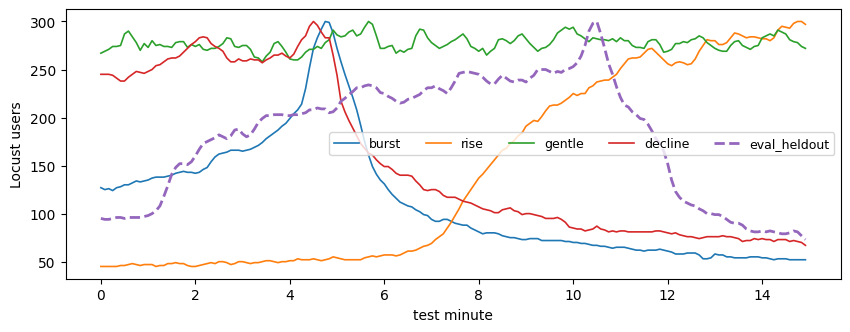

,t_sec,users
0,0,127
1,5,125
2,10,126
3,15,124
4,20,127


In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name in ["burst", "rise", "gentle", "decline", "eval_heldout"]:
    w = pd.read_csv(R("workloads", f"{name}.csv"))
    ax.plot(w.t_sec / 60, w.users, label=name, lw=2 if name == "eval_heldout" else 1.2,
            ls="--" if name == "eval_heldout" else "-")
ax.set_xlabel("test minute"); ax.set_ylabel("Locust users"); ax.legend(ncol=5, fontsize=9); plt.show()
pd.read_csv(R("workloads", "burst.csv")).head()

## 2. Raw data recorded during one run
`run_mech.sh` resets the shop, turns on ONE scaling method for all services, replays a traffic shape with
Locust, and `collector.py` records every service every 15 seconds (Linkerd/Prometheus for traffic and
latency, metrics-server for CPU). Example: KEDA, rise shape, repeat 1.

> **Write here:** what each column means (t_sec, rps, p95_ms, cpu_m, req_m_pod, replicas).

In [ ]:
raw = pd.read_csv(R("results", "mech", "keda_rise_run1_metrics.csv"))
print(raw.shape, "rows =", raw.t_sec.nunique(), "samples x", raw.service.nunique(), "services")
raw[raw.service == "frontend"].head(8)

(704, 10) rows = 64 samples x 11 services


,t_sec,service,mechanism,rps,p95_ms,success,cpu_m,req_m_pod,replicas,cpu_util
0,0.0,frontend,keda,2.944,1774.0,0.8639,0.3,100.0,1,0.0029
11,15.0,frontend,keda,8.787,1166.9,1.0561,20.8,100.0,1,0.2079
22,30.0,frontend,keda,17.936,650.4,0.9970,99.3,100.0,1,0.9935
33,45.0,frontend,keda,25.278,450.3,1.0017,109.1,100.0,1,1.0910
44,60.0,frontend,keda,30.762,89.6,0.9987,109.4,100.0,2,0.5472
55,75.0,frontend,keda,31.876,84.4,0.9995,112.8,100.0,2,0.5641
66,90.0,frontend,keda,32.314,84.6,0.9984,120.1,100.0,2,0.6004
77,105.0,frontend,keda,32.959,87.9,0.9985,110.9,100.0,3,0.3696


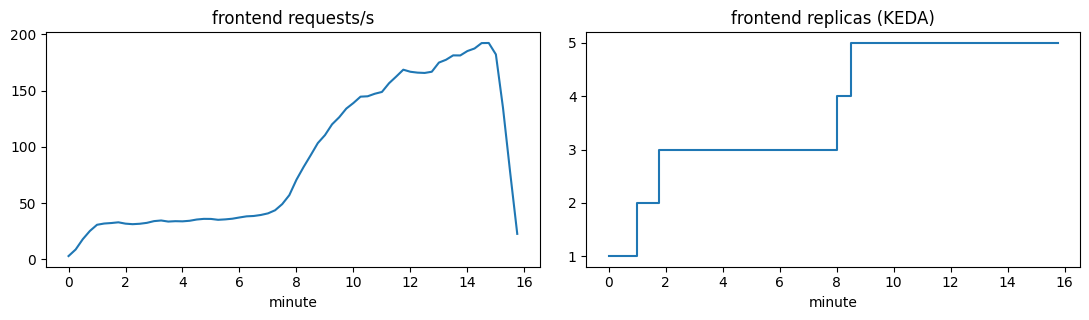

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
fe = raw[raw.service == "frontend"]
ax[0].plot(fe.t_sec / 60, fe.rps); ax[0].set_title("frontend requests/s"); ax[0].set_xlabel("minute")
ax[1].plot(fe.t_sec / 60, fe.replicas, drawstyle="steps-post"); ax[1].set_title("frontend replicas (KEDA)")
ax[1].set_xlabel("minute"); plt.tight_layout(); plt.show()

## 3. Labels: which method was best in each service-minute?
The same traffic was run three times (HPA only, KEDA only, vertical only), twice each.
`make_labels.py` scores each method per service and minute:
score = 0.6 x SLO-violation share + 0.3 x relative CPU reserved + 0.1 x scaling actions (lower is better).

> **Write here:** why these three parts and weights (cite Rossi et al.), and why the first minute is skipped.

In [ ]:
lab = pd.read_csv(R("results", "labels", "rise_run1_w60_floor50_labels.csv"))
lab[lab.service == "frontend"].head(8)

,service,win,hpa,keda,vertical,label,margin
70,frontend,1,0.300000,0.202083,0.136500,vertical,0.065583
71,frontend,2,0.300000,0.225000,0.162708,vertical,0.062292
72,frontend,3,0.300000,0.225000,0.122250,vertical,0.102750
73,frontend,4,0.300000,0.225000,0.122250,vertical,0.102750
74,frontend,5,0.333333,0.200000,0.108667,vertical,0.091333
75,frontend,6,0.300000,0.180000,0.161467,vertical,0.018533
76,frontend,7,0.300000,0.180000,0.182167,keda,0.002167
77,frontend,8,0.300000,0.336667,0.226267,vertical,0.073733


In [ ]:
shares = []
for s in ["burst", "rise", "gentle", "decline"]:
    for r in [1, 2]:
        l = pd.read_csv(R("results", "labels", f"{s}_run{r}_w60_floor50_labels.csv"))
        shares.append({"shape": s, "run": r, **(l.label.value_counts(normalize=True) * 100).round(1).to_dict()})
pd.DataFrame(shares).fillna(0)

,shape,run,vertical,keda,hpa
0,burst,1,83.6,10.7,5.7
1,burst,2,88.6,10.0,1.4
2,rise,1,72.1,9.3,18.6
3,rise,2,74.3,10.0,15.7
4,gentle,1,67.1,20.7,12.1
5,gentle,2,95.7,1.4,2.9
6,decline,1,85.0,5.0,10.0
7,decline,2,85.0,9.3,5.7


### 3.1 How reliable are the labels? (two identical runs compared)
> **Write here:** what the agreement table shows about HPA/KEDA wins, and what it means for any classifier.

In [ ]:
from sklearn.metrics import cohen_kappa_score, f1_score
agree = []
for s in ["burst", "rise", "gentle", "decline"]:
    a = pd.read_csv(R("results", "labels", f"{s}_run1_w60_floor50_labels.csv"))[["service", "win", "label"]]
    b = pd.read_csv(R("results", "labels", f"{s}_run2_w60_floor50_labels.csv"))[["service", "win", "label"]]
    agree.append(a.merge(b, on=["service", "win"], suffixes=("_run1", "_run2")))
A = pd.concat(agree, ignore_index=True)
print(f"agreement {np.mean(A.label_run1 == A.label_run2)*100:.1f}%   kappa {cohen_kappa_score(A.label_run1, A.label_run2):.2f}")
print("3-class noise ceiling (macro-F1 of run 2 vs run 1):", round(f1_score(A.label_run1, A.label_run2, average='macro'), 3))
B = A.replace({"hpa": "horizontal", "keda": "horizontal"})
print("binary  noise ceiling (scale up vs out):         ", round(f1_score(B.label_run1, B.label_run2, average='macro'), 3))
pd.crosstab(A.label_run1, A.label_run2)

agreement 78.0%   kappa 0.32
3-class noise ceiling (macro-F1 of run 2 vs run 1): 0.524
binary  noise ceiling (scale up vs out):          0.675


label_run2,hpa,keda,vertical
label_run1,,,
hpa,17,8,40
keda,5,19,40
vertical,14,16,401


## 4. The exact table fed to the models
Built by `train_selector.py --runs 1 2 --avg --task binary --lags`: for each service and minute, the
features come from the PREVIOUS minute(s) only, and the label is the method with the lowest average score
over both repeats. Binary task: vertical (scale up) vs horizontal (scale out, executed as KEDA).

> **Write here:** what each feature means and why only earlier minutes are used.

In [ ]:
D = pd.read_csv(R("results", "selector", "training_dataset_floor50_avg12_binary_lags.csv"))
print(D.shape); print(D.label.value_counts(normalize=True).round(3))
D.head()

(560, 21)
label
vertical      0.777
horizontal    0.223
Name: proportion, dtype: float64


,shape,run,service,minute,rps,slope,burst,peak_ratio,fe_rps,fe_slope,forecast,rps_lag1,rps_lag2,slope_lag1,rps_roll3,accel,score_hpa,score_keda,score_vertical,label,reliable
0,burst,avg,adservice,1,11.260458,0.000000,0.730051,2.232858,28.288958,0.000000,11.260458,11.260458,11.260458,0.000000,11.260458,0.000000,0.408333,0.621429,0.558381,horizontal,False
1,burst,avg,adservice,2,29.828458,18.568000,0.075410,1.128453,79.405667,51.116708,48.396458,11.260458,29.828458,0.000000,20.544458,18.568000,0.300000,0.150000,0.156750,horizontal,False
2,burst,avg,adservice,3,34.208083,4.379625,0.053507,1.106756,91.801333,12.395667,38.587708,29.828458,11.260458,18.568000,25.099000,-14.188375,0.300000,0.150000,0.574646,horizontal,True
3,burst,avg,adservice,4,39.170792,4.962708,0.039357,1.075291,104.128375,12.327042,44.133500,34.208083,29.828458,4.379625,34.402444,0.583083,0.300000,0.150000,0.104792,vertical,True
4,burst,avg,adservice,5,48.492625,9.321833,0.117885,1.219567,127.632917,23.504542,57.814458,39.170792,34.208083,4.962708,40.623833,4.359125,0.300000,0.258333,0.115271,vertical,True


### 4.1 Tracing one row back to the raw data
> **Write here:** explain this example in your own words (inputs from minute 7, label from minute 8).

In [ ]:
shape, svc, minute = "rise", "frontend", 8          # change these to trace another row
row = D[(D["shape"] == shape) & (D.service == svc) & (D.minute == minute)]
display(row.T)
rawall = pd.concat([pd.read_csv(R("results", "mech", f"{m}_{shape}_run{r}_metrics.csv"))
                    for m in ["hpa", "keda", "vertical"] for r in [1, 2]])
prev = rawall[(rawall.service == svc) & (rawall.t_sec // 60 == minute - 1)]
print(f"raw rps in minute {minute-1}: {len(prev)} samples (6 runs x 4), mean = {prev.rps.mean():.3f}")
det = pd.concat([pd.read_csv(R("results", "labels", f"{shape}_run{r}_w60_floor50_window_details.csv")) for r in [1, 2]])
sc = det[(det.service == svc) & (det.win == minute)].groupby("mechanism").score.mean()
print(f"average score per method in minute {minute}:"); print(sc.round(3)); print("winner:", sc.idxmin())

,217
shape,rise
run,avg
service,frontend
minute,8
rps,48.282667
slope,10.117292
burst,0.135006
peak_ratio,1.241439
fe_rps,48.282667
fe_slope,10.117292


raw rps in minute 7: 24 samples (6 runs x 4), mean = 48.283
average score per method in minute 8:
mechanism
hpa         0.375
keda        0.337
vertical    0.444
Name: score, dtype: float64
winner: keda


## 5. Models (RQ2): leave-one-shape-out
Every model is trained on three traffic shapes and tested on the fourth, four times. A small live
demonstration with ExtraTrees (class_weight="balanced") and the chance level, then the saved results of
all steps.

> **Write here:** why leave-one-shape-out, and why macro-F1 and regret rather than accuracy.

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, confusion_matrix
FEATS = ["rps", "slope", "burst", "peak_ratio", "fe_rps", "fe_slope", "forecast",
         "rps_lag1", "rps_lag2", "slope_lag1", "rps_roll3", "accel"]
X = pd.concat([D[FEATS], pd.get_dummies(D.service, prefix="svc").astype(float)], axis=1)
y = D.label.values
for name, model in [("ExtraTrees (balanced)", ExtraTreesClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2, random_state=0)),
                    ("chance (stratified coin)", DummyClassifier(strategy="stratified", random_state=0))]:
    pred = np.empty(len(y), dtype=object)
    for s in D["shape"].unique():
        te = (D["shape"] == s).values
        pred[te] = model.fit(X[~te], y[~te]).predict(X[te])
    print(f"{name:26s} macro-F1 = {f1_score(y, pred, average='macro'):.3f}")

ExtraTrees (balanced)      macro-F1 = 0.741
chance (stratified coin)   macro-F1 = 0.516


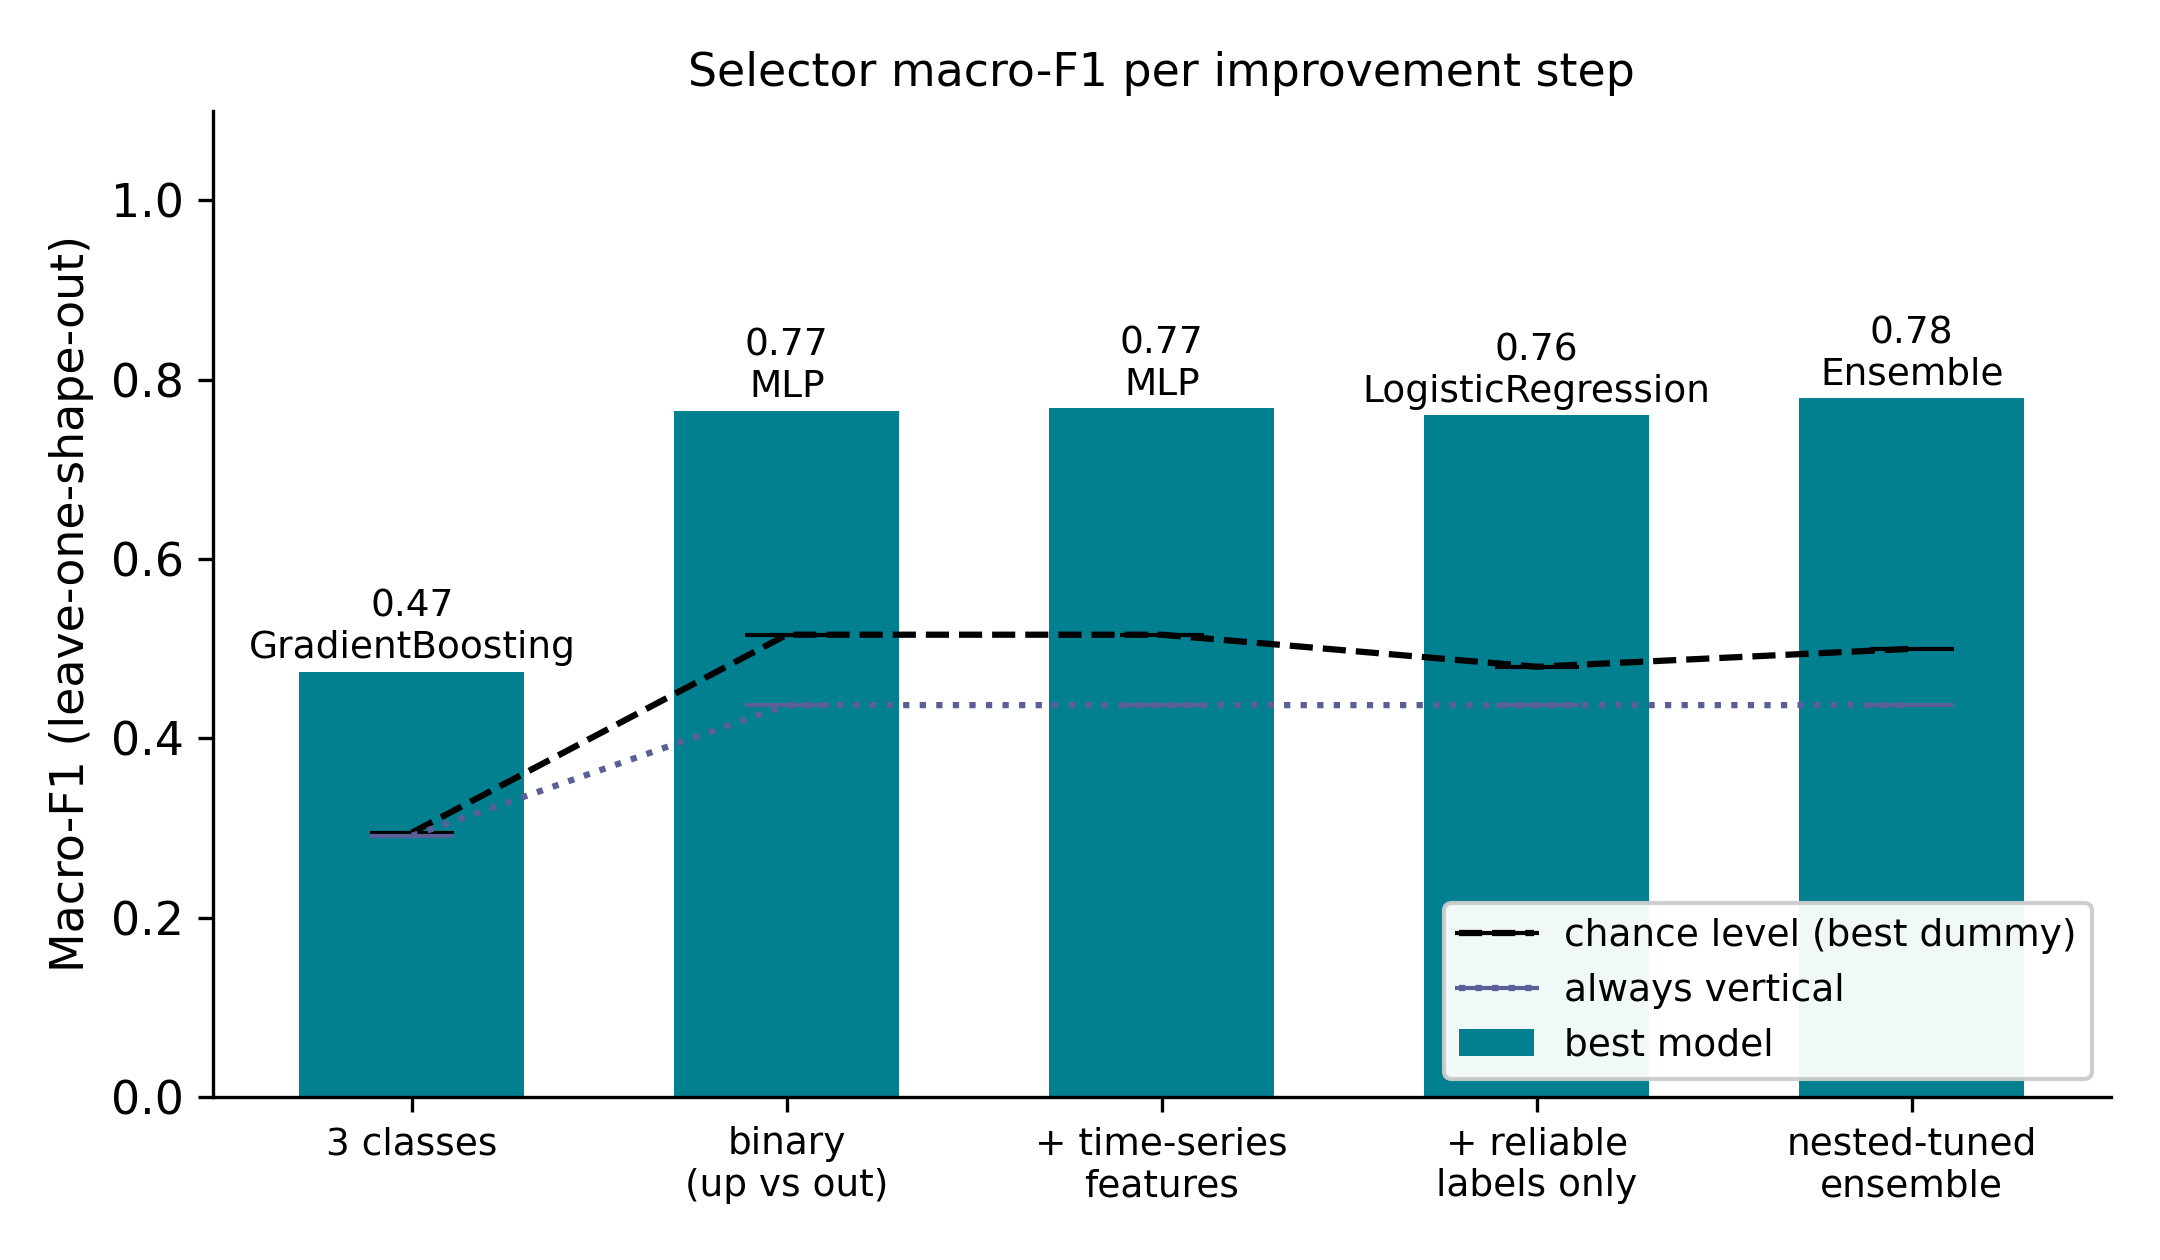

,step,best_model,macro_F1,chance,always_vertical
0,3 classes,GradientBoosting,0.474520,0.294942,0.291457
1,binary\n(up vs out),MLP,0.765239,0.515675,0.437186
2,+ time-series\nfeatures,MLP,0.768211,0.515675,0.437186
3,+ reliable\nlabels only,LogisticRegression,0.760270,0.479962,0.437186
4,nested-tuned\nensemble,Ensemble_tuned,0.779254,0.500000,0.437186


In [ ]:
display(Image(R("results", "figures", "fig_f1_steps.png"), width=700))
pd.read_csv(R("results", "figures", "fig_f1_steps_data.csv"))

In [ ]:
tuned = pd.read_csv(R("results", "selector", "rq2_tuned_binary_lags.csv"))
display(tuned.round(4))
pd.read_csv(R("results", "selector", "rq2_tuned_binary_lags_per_class.csv")).round(3)

,model,accuracy,macro_F1,mean_regret,diff_vs_vertical,ci_low,ci_high,wilcoxon_p,horizontal_%
0,Ensemble_tuned,0.8518,0.7793,0.0281,-0.0084,-0.0160,-0.0010,0.0113,20.3571
1,kNN_tuned,0.8500,0.7773,0.0270,-0.0095,-0.0164,-0.0020,0.0048,20.5357
2,MLP_tuned,0.8393,0.7628,0.0308,-0.0057,-0.0135,0.0019,0.0810,20.8929
3,MLP_default,0.8357,0.7530,0.0311,-0.0055,-0.0124,0.0015,0.0518,19.8214
4,kNN_default,0.8286,0.7470,0.0311,-0.0054,-0.0128,0.0015,0.0674,20.8929
5,ExtraTrees_default,0.8107,0.7414,0.0315,-0.0050,-0.0131,0.0031,0.1533,25.8929
6,ExtraTrees_tuned,0.7661,0.7084,0.0370,0.0005,-0.0085,0.0095,0.9085,33.2143
7,always_vertical,0.7768,0.4372,0.0365,0.0000,0.0000,0.0000,NaN,0.0000


,model,class,precision,recall,f1-score,support
0,Ensemble_tuned,vertical,0.895,0.917,0.906,435.0
1,Ensemble_tuned,horizontal,0.684,0.624,0.653,125.0
2,kNN_tuned,vertical,0.894,0.915,0.905,435.0
3,kNN_tuned,horizontal,0.678,0.624,0.650,125.0
4,always_vertical,vertical,0.777,1.000,0.874,435.0
5,always_vertical,horizontal,0.000,0.000,0.000,125.0


### 5.1 The final selector (fixed before the live test)
`build_final_model.py` chose these settings on the four training shapes; `live_selector.py` trains the
ensemble with them at start-up.

> **Write here:** what the ensemble is, what the 0.6 threshold means, and why horizontal = KEDA.

In [ ]:
json.load(open(R("results", "selector", "final_selector.json")))["models"], \
json.load(open(R("results", "selector", "final_selector.json")))["threshold"]

C:\Users\anany\AppData\Local\Temp\ipykernel_14376\1917130164.py:1: ResourceWarning: unclosed file <_io.TextIOWrapper name='..\\results\\selector\\final_selector.json' mode='r' encoding='cp1252'>
  json.load(open(R("results", "selector", "final_selector.json")))["models"], \
C:\Users\anany\AppData\Local\Temp\ipykernel_14376\1917130164.py:2: ResourceWarning: unclosed file <_io.TextIOWrapper name='..\\results\\selector\\final_selector.json' mode='r' encoding='cp1252'>
  json.load(open(R("results", "selector", "final_selector.json")))["threshold"]


({'MLP': {'h': [64], 'alpha': 0.01},
  'ExtraTrees': {'depth': 10, 'leaf': 1, 'feat': 'sqrt'},
  'kNN': {'k': 5, 'w': 'distance'}},
 0.6)

## 6. Live evaluation (RQ3) on the held-out traffic
Five methods, three runs each, on `eval_heldout` (never used for training or model choice).
Computed by `analyze_eval.py` (steady part 60-900 s; Welch t-tests with Holm correction).

> **Write here:** the main result, which differences are significant, and the limitations (n = 3,
> different lab/day for rules and selector, checked with an extra vertical run).

In [ ]:
display(pd.read_csv(R("results", "eval", "summary.csv")))
pd.read_csv(R("results", "eval", "tests.csv")).round(4)

,method,n,slo_viol_%,fe_p95_ms,locust_p50_ms,locust_p95_ms,locust_p99_ms,locust_avg_ms,cpu_alloc_m,replicas,replica_changes,resizes,switches,failures_%,throughput_rps
0,vertical,3,18.5 ± 30.2,357.5 ± 250.0,84.3 ± 79.6,590.0 ± 286.5,1100.0 ± 248.4,153.5 ± 111.0,1662.4 ± 125.7,10.0 ± 0.0,0.0 ± 0.0,67.7 ± 9.4,0.0 ± 0.0,0.0 ± 0.0,84.9 ± 4.4
1,hpa,3,0.6 ± 2.6,252.5 ± 67.6,83.7 ± 15.0,340.0 ± 89.6,866.7 ± 62.5,138.6 ± 24.0,3544.6 ± 158.8,30.6 ± 0.8,13.0 ± 2.5,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,85.7 ± 1.2
2,keda,3,3.6 ± 4.4,257.6 ± 78.6,87.7 ± 29.0,343.3 ± 112.0,860.0 ± 237.0,139.4 ± 41.4,3007.1 ± 38.4,26.2 ± 0.3,14.0 ± 2.5,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,85.7 ± 0.7
3,rules,3,15.5 ± 24.4,309.1 ± 145.8,73.0 ± 21.2,486.7 ± 179.7,1166.7 ± 143.4,138.1 ± 35.1,2109.6 ± 285.4,14.1 ± 1.8,18.0 ± 15.1,88.7 ± 33.1,24.7 ± 20.1,0.0 ± 0.0,85.4 ± 1.8
4,selector,3,0.6 ± 2.6,218.8 ± 90.1,79.3 ± 29.6,283.3 ± 141.3,966.7 ± 312.6,119.2 ± 48.1,2081.3 ± 55.9,14.3 ± 0.1,12.3 ± 1.4,70.0 ± 20.3,10.0 ± 0.0,0.0 ± 0.0,86.3 ± 1.6


,metric,vs,selector_mean,other_mean,p,p_holm
0,cpu_alloc_m,keda,2081.2857,3007.1429,0.0000,0.0000
1,cpu_alloc_m,hpa,2081.2857,3544.6429,0.0002,0.0026
2,cpu_alloc_m,vertical,2081.2857,1662.4464,0.0014,0.0202
3,locust_p95_ms,rules,283.3333,486.6667,0.0206,0.2681
4,locust_p95_ms,vertical,283.3333,590.0000,0.0271,0.3257
5,slo_viol_%,keda,0.5952,3.5714,0.0824,0.9069
6,fe_p95_ms,rules,218.8411,309.0714,0.0995,0.9953
7,slo_viol_%,rules,0.5952,15.4762,0.1184,1.0000
8,slo_viol_%,vertical,0.5952,18.4524,0.1249,1.0000
9,fe_p95_ms,vertical,218.8411,357.5089,0.1276,1.0000


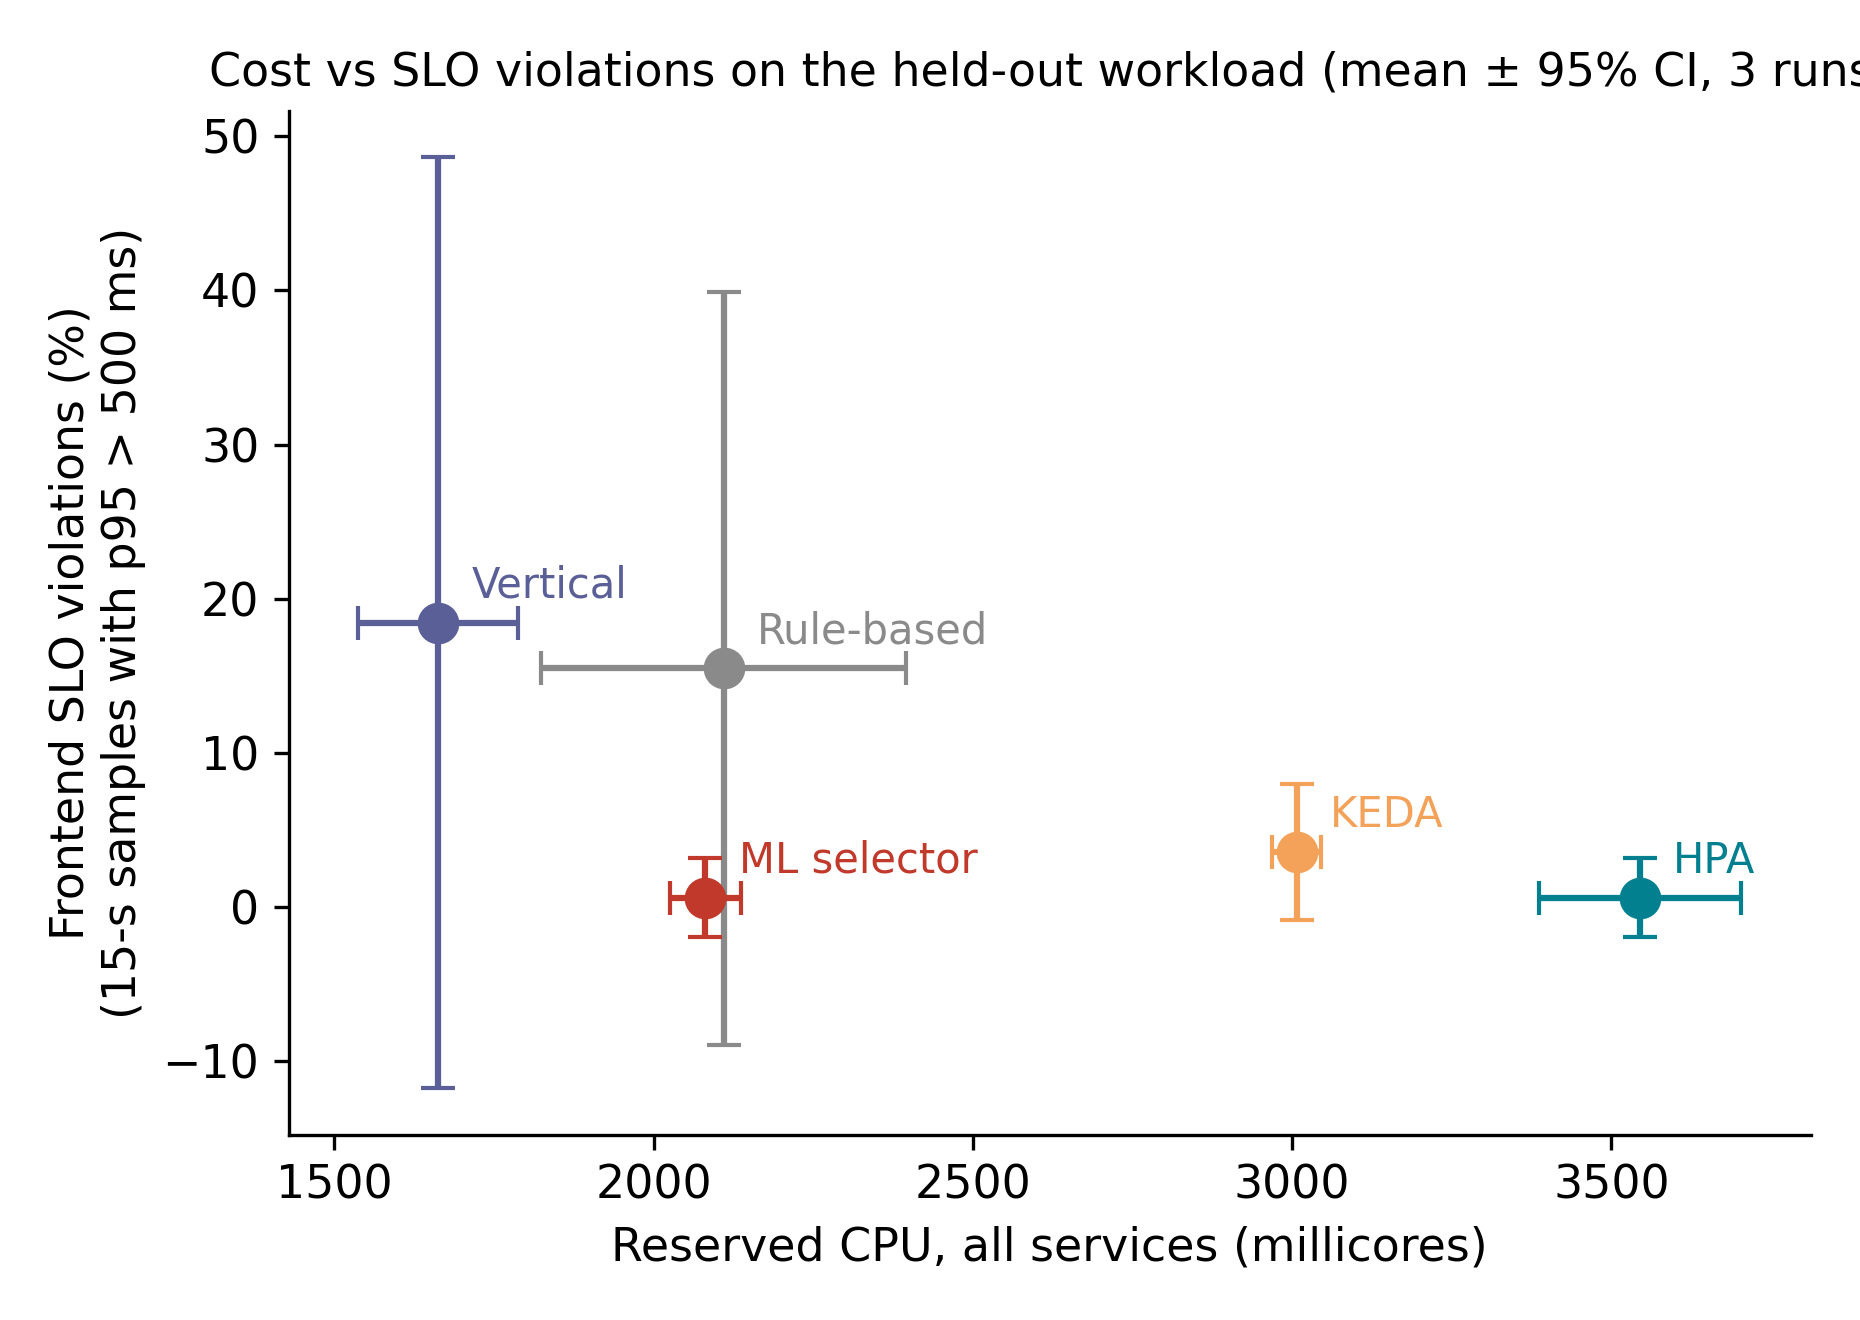

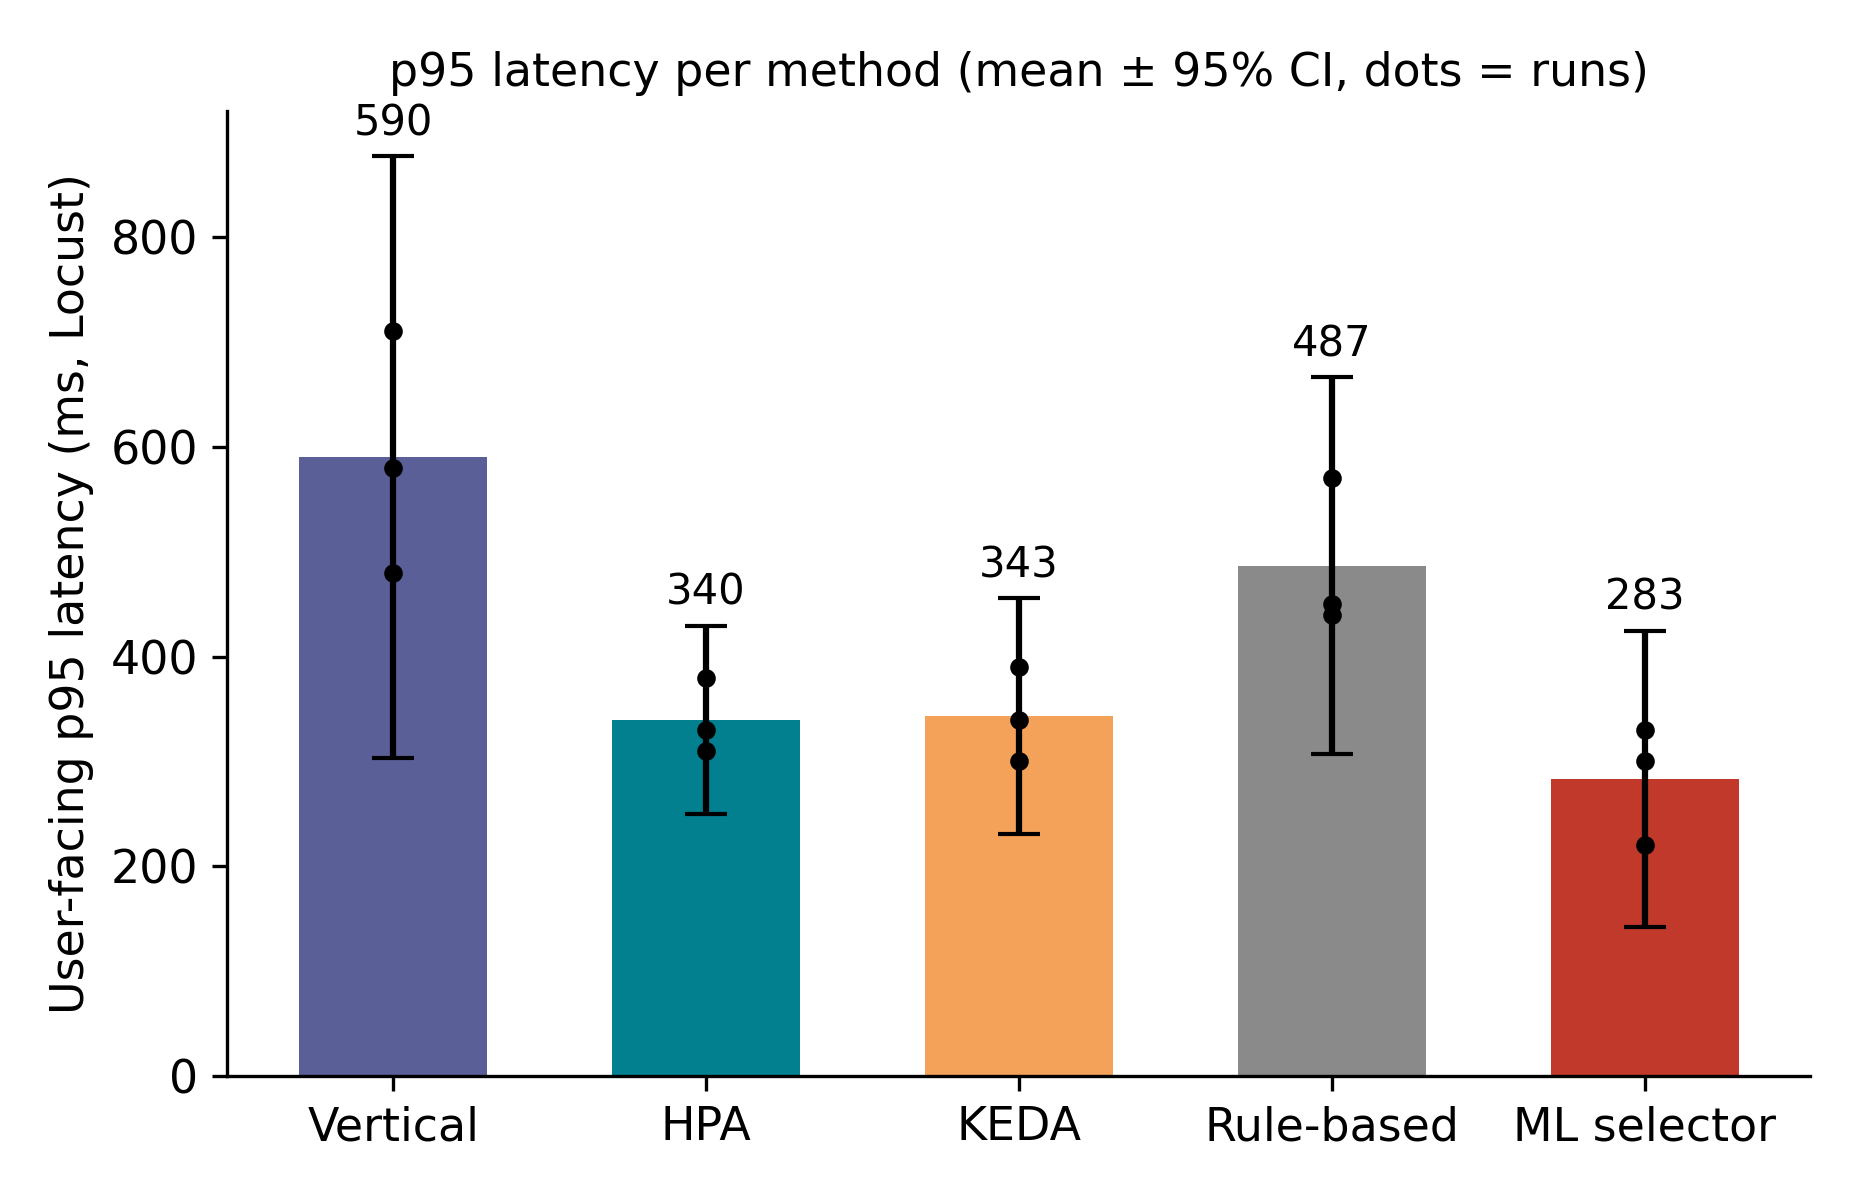

In [ ]:
display(Image(R("results", "figures", "fig_tradeoff.png"), width=600))
display(Image(R("results", "figures", "fig_latency.png"), width=600))

In [ ]:
# same-day check: vertical run 4 (new lab) against vertical runs 1-3 (earlier lab)
pr = pd.read_csv(R("results", "eval", "per_run.csv")); v4 = pd.read_csv(R("results", "eval", "per_run_vertical4.csv"))
pd.concat([pr[pr.method == "vertical"], v4])[["method", "run", "slo_viol_%", "fe_p95_ms", "locust_p95_ms", "cpu_alloc_m"]].round(1)

,method,run,slo_viol_%,fe_p95_ms,locust_p95_ms,cpu_alloc_m
0,vertical,1,32.1,469.8,710,1607.6
1,vertical,2,8.9,327.5,580,1707.3
2,vertical,3,14.3,275.3,480,1672.4
0,vertical,4,28.6,427.6,670,1620.8


## 7. ML checks (standard good practice)
Exploratory data analysis, per-fold variation, error analysis, permutation importance, an overfitting
check and a learning curve. These use the FINAL selector settings (`final_selector.json`) with
leave-one-shape-out. Note: those settings were chosen on all four shapes, so these per-fold numbers are
slightly optimistic; the unbiased overall estimate is the nested result in section 5 (macro-F1 0.779).

> **Write here (after running):** one or two sentences per check: what you see and what it means.

In [ ]:
# shared setup: the final ensemble as one scikit-learn style classifier
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score
cfg = json.load(open(R("results", "selector", "final_selector.json")))
g, THR = cfg["models"], cfg["threshold"]

class FinalEnsemble(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.models_ = [
            make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=tuple(g["MLP"]["h"]), alpha=g["MLP"]["alpha"], max_iter=2000, random_state=0)),
            ExtraTreesClassifier(n_estimators=300, max_depth=g["ExtraTrees"]["depth"], min_samples_leaf=g["ExtraTrees"]["leaf"],
                                 max_features=g["ExtraTrees"]["feat"], class_weight="balanced", random_state=0, n_jobs=-1),
            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=g["kNN"]["k"], weights=g["kNN"]["w"]))]
        for m in self.models_: m.fit(X, y)
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models_], axis=0); return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= THR).astype(int)

Xb = pd.concat([D[cfg["features"]].astype(float), pd.get_dummies(D.service, prefix="svc").astype(float)], axis=1)[cfg["columns"]]
yb = (D.label == "horizontal").astype(int).values
shapes = D["shape"].values
pred = np.zeros(len(yb), int); fold_rows = []
for s in dict.fromkeys(shapes):
    te = shapes == s
    m = FinalEnsemble().fit(Xb[~te], yb[~te])
    pred[te] = m.predict(Xb[te])
    fold_rows.append({"held_out_shape": s, "test_macro_F1": f1_score(yb[te], pred[te], average="macro"),
                      "train_macro_F1": f1_score(yb[~te], m.predict(Xb[~te]), average="macro"),
                      "horizontal_share_%": 100 * yb[te].mean()})
print("overall leave-one-shape-out macro-F1 with the final settings:", round(f1_score(yb, pred, average="macro"), 3))

C:\Users\anany\AppData\Local\Temp\ipykernel_14376\1115531322.py:9: ResourceWarning: unclosed file <_io.TextIOWrapper name='..\\results\\selector\\final_selector.json' mode='r' encoding='cp1252'>
  cfg = json.load(open(R("results", "selector", "final_selector.json")))


overall leave-one-shape-out macro-F1 with the final settings: 0.783


### 7.1 Exploratory data analysis: do the features differ between the two classes?

label,median (horizontal),median (vertical)
rps,59.87,39.80
slope,1.22,0.20
burst,0.06,0.06
peak_ratio,1.12,1.11
fe_rps,142.07,84.24
fe_slope,5.16,0.82
forecast,61.41,35.92
rps_lag1,50.16,37.78
rps_lag2,38.63,39.20
slope_lag1,1.13,0.03


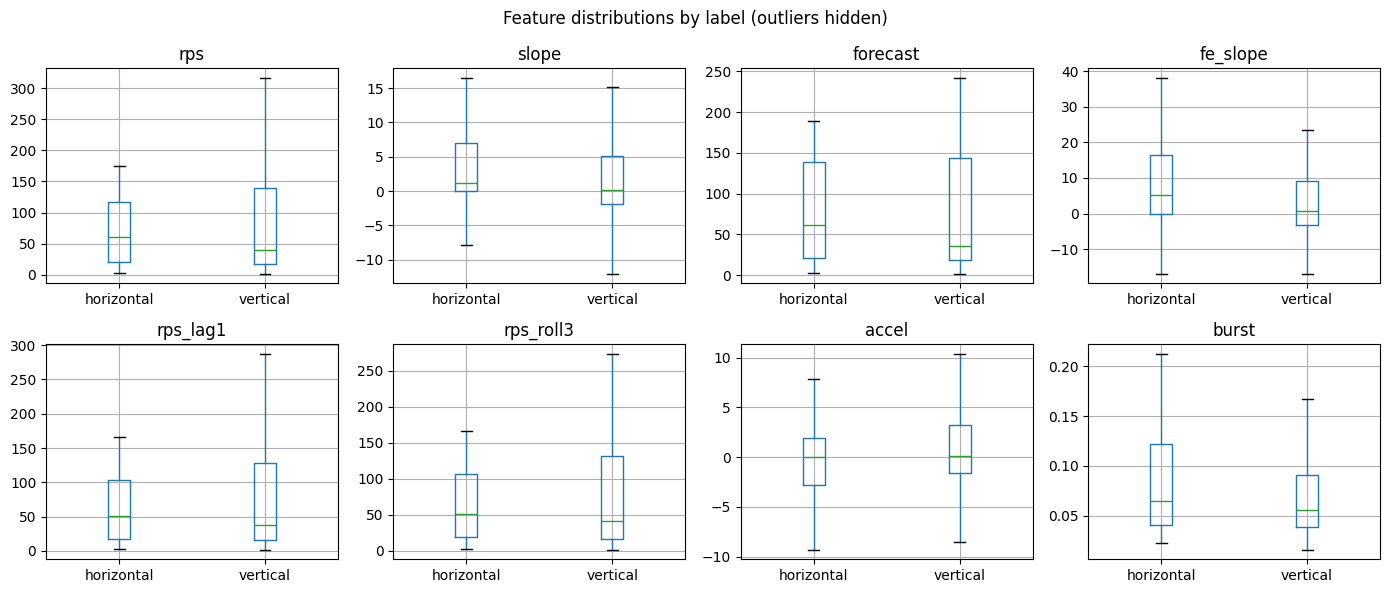

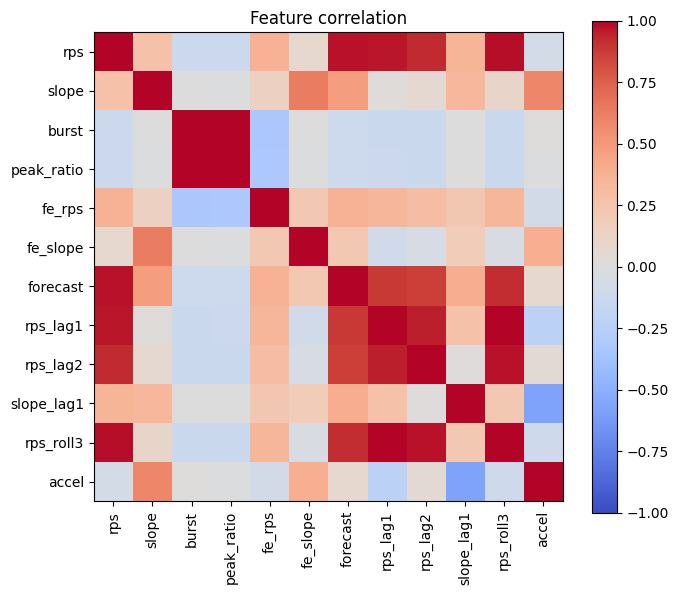

In [ ]:
feat = cfg["features"]
display(D.groupby("label")[feat].median().T.round(2).rename(columns=lambda c: f"median ({c})"))
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, f in zip(axs.ravel(), ["rps", "slope", "forecast", "fe_slope", "rps_lag1", "rps_roll3", "accel", "burst"]):
    D.boxplot(column=f, by="label", ax=ax, showfliers=False); ax.set_title(f); ax.set_xlabel("")
plt.suptitle("Feature distributions by label (outliers hidden)"); plt.tight_layout(); plt.show()
corr = D[feat].corr()
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat))); ax.set_xticklabels(feat, rotation=90); ax.set_yticks(range(len(feat))); ax.set_yticklabels(feat)
plt.colorbar(im); ax.set_title("Feature correlation"); plt.tight_layout(); plt.show()

### 7.2 Variation across held-out shapes and overfitting check
Train vs test macro-F1 per fold: a large gap means the model memorises the training shapes.

In [ ]:
F = pd.DataFrame(fold_rows); F["gap"] = F.train_macro_F1 - F.test_macro_F1
display(F.round(3))
print(f"test macro-F1 across shapes: mean {F.test_macro_F1.mean():.3f}, sd {F.test_macro_F1.std(ddof=1):.3f}, "
      f"min {F.test_macro_F1.min():.3f}, max {F.test_macro_F1.max():.3f}")

,held_out_shape,test_macro_F1,train_macro_F1,horizontal_share_%,gap
0,burst,0.722,0.971,13.571,0.248
1,rise,0.717,0.992,29.286,0.275
2,gentle,0.841,0.973,30.000,0.131
3,decline,0.767,0.970,16.429,0.203


test macro-F1 across shapes: mean 0.762, sd 0.058, min 0.717, max 0.841


### 7.3 Error analysis: where does the model struggle?

In [ ]:
E = D[["shape", "service"]].copy(); E["true"] = yb; E["pred"] = pred
rows = []
for svc, d in E.groupby("service"):
    rows.append({"service": svc, "horizontal_true": int(d.true.sum()), "horizontal_pred": int(d.pred.sum()),
                 "accuracy": (d.true == d.pred).mean(),
                 "macro_F1": f1_score(d.true, d.pred, average="macro", labels=[0, 1], zero_division=0)})
display(pd.DataFrame(rows).set_index("service").sort_values("macro_F1").round(3))
rows = []
for shp, d in E.groupby("shape"):
    rows.append({"shape": shp, "accuracy": (d.true == d.pred).mean(),
                 "missed_scale_out": int(((d.true == 1) & (d.pred == 0)).sum()),
                 "false_scale_out": int(((d.true == 0) & (d.pred == 1)).sum())})
pd.DataFrame(rows).set_index("shape").round(3)

,horizontal_true,horizontal_pred,accuracy,macro_F1
service,,,,
frontend,19,12,0.554,0.442
currencyservice,3,2,0.911,0.477
emailservice,3,0,0.946,0.486
paymentservice,0,0,1.000,0.500
productcatalogservice,0,0,1.000,0.500
shippingservice,0,0,1.000,0.500
adservice,14,6,0.786,0.635
recommendationservice,31,31,0.786,0.783
checkoutservice,27,27,0.786,0.785


,accuracy,missed_scale_out,false_scale_out
shape,,,
burst,0.879,10,7
decline,0.886,11,5
gentle,0.857,4,16
rise,0.807,24,3


### 7.3b Does the model beat a simple per-service lookup?
The service name is the strongest input (7.4), so the obvious simpler alternative is a lookup table:
for each service, always choose what that service needed most often in the TRAINING shapes
(leave-one-shape-out, ties -> vertical). If the model is clearly better, the traffic features add value.

> **Write here:** what the comparison shows and what it means for the contribution of ML.

In [ ]:
def regret_of(p):                                   # horizontal is executed as KEDA
    chosen = np.where(p == 1, D.score_keda.values, D.score_vertical.values)
    return chosen - D[["score_hpa", "score_keda", "score_vertical"]].min(axis=1).values

lookup = np.zeros(len(yb), int)
for s in dict.fromkeys(shapes):
    te = shapes == s
    share = pd.Series(yb[~te]).groupby(D.service.values[~te]).mean()      # share of 'horizontal' per service
    lookup[te] = (D.service[te].map(share).fillna(0).values > 0.5).astype(int)

cmp_rows = []
for name, p in [("always vertical", np.zeros(len(yb), int)), ("per-service lookup", lookup),
                ("final ensemble (final settings)", pred)]:
    cmp_rows.append({"strategy": name, "macro_F1": f1_score(yb, p, average="macro"),
                     "accuracy": (p == yb).mean(), "mean_regret": regret_of(p).mean(),
                     "scale_out_%": 100 * p.mean()})
display(pd.DataFrame(cmp_rows).round(4))
print("services the lookup sends to scale-out:",
      sorted(D.service[lookup == 1].unique()))

# paired comparison: ensemble vs lookup (same service-minutes)
diff = regret_of(pred) - regret_of(lookup)
rng = np.random.default_rng(0)
boots = [rng.choice(diff, len(diff)).mean() for _ in range(2000)]
lo, hi = np.percentile(boots, [2.5, 97.5])
from scipy.stats import wilcoxon
print(f"regret: ensemble - lookup = {diff.mean():+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}], "
      f"Wilcoxon p = {wilcoxon(regret_of(pred), regret_of(lookup)).pvalue:.3g}  (negative = ensemble better)")
f1_boot = []
for _ in range(2000):
    i = rng.integers(0, len(yb), len(yb))
    f1_boot.append(f1_score(yb[i], pred[i], average="macro") - f1_score(yb[i], lookup[i], average="macro"))
print(f"macro-F1: ensemble - lookup = {np.mean(f1_boot):+.3f}, 95% CI {np.percentile(f1_boot, [2.5, 97.5]).round(3)}")

,strategy,macro_F1,accuracy,mean_regret,scale_out_%
0,always vertical,0.4372,0.7768,0.0365,0.0000
1,per-service lookup,0.5064,0.7161,0.0411,12.5000
2,final ensemble (final settings),0.7825,0.8571,0.0273,19.1071


services the lookup sends to scale-out: ['cartservice', 'checkoutservice', 'recommendationservice']
regret: ensemble - lookup = -0.0138, 95% CI [-0.0198, -0.0074], Wilcoxon p = 1.01e-06  (negative = ensemble better)
macro-F1: ensemble - lookup = +0.276, 95% CI [0.227 0.328]


### 7.4 Permutation importance (on held-out shapes)
How much does macro-F1 drop when one feature is shuffled? The service one-hot columns are shuffled
together as one feature, "service". Computed on the held-out shape of every fold, 5 repeats.

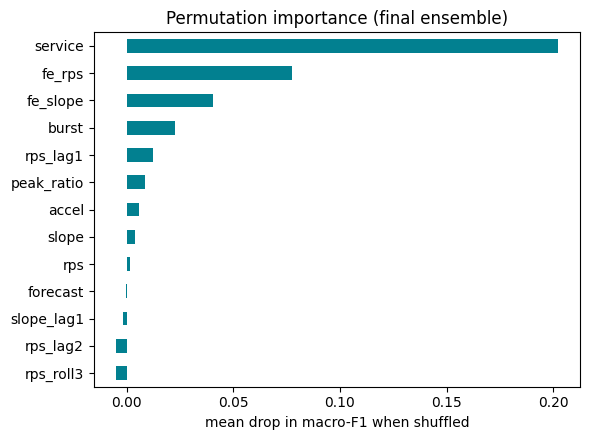

service       0.2021
fe_rps        0.0777
fe_slope      0.0404
burst         0.0228
rps_lag1      0.0123
peak_ratio    0.0088
accel         0.0058
slope         0.0042
rps           0.0015
forecast     -0.0004
slope_lag1   -0.0015
rps_lag2     -0.0048
rps_roll3    -0.0049
dtype: float64

In [ ]:
rng = np.random.default_rng(0)
groups = {f: [f] for f in cfg["features"]}
groups["service"] = [c for c in cfg["columns"] if c.startswith("svc_")]
drops = {k: [] for k in groups}
for s in dict.fromkeys(shapes):
    te = shapes == s
    m = FinalEnsemble().fit(Xb[~te], yb[~te])
    Xt = Xb[te].reset_index(drop=True); base = f1_score(yb[te], m.predict(Xt), average="macro")
    for k, cols in groups.items():
        for _ in range(5):
            Xp = Xt.copy(); idx = rng.permutation(len(Xp)); Xp[cols] = Xt[cols].values[idx]
            drops[k].append(base - f1_score(yb[te], m.predict(Xp), average="macro"))
PI = pd.Series({k: np.mean(v) for k, v in drops.items()}).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(6, 4.5)); PI.plot.barh(ax=ax, color="#028090")
ax.set_xlabel("mean drop in macro-F1 when shuffled"); ax.set_title("Permutation importance (final ensemble)")
plt.tight_layout(); plt.show(); PI.sort_values(ascending=False).round(4)

### 7.5 Learning curve: would more training data help?
Train on a random fraction of the training rows of each fold (3 random seeds), test on the held-out shape.

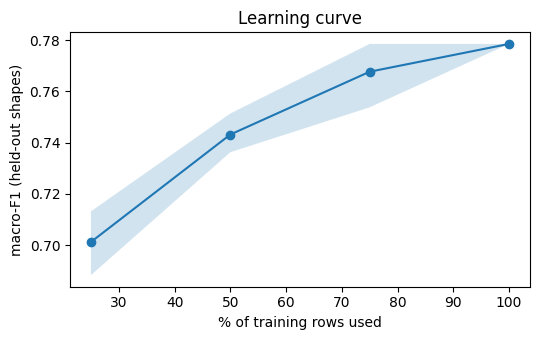

,mean,min,max
fraction,,,
0.25,0.701,0.688,0.713
0.50,0.743,0.736,0.751
0.75,0.768,0.754,0.779
1.00,0.779,0.779,0.779


In [ ]:
LC = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    for seed in ([0] if frac == 1.0 else [0, 1, 2]):
        p = np.zeros(len(yb), int); r = np.random.default_rng(seed)
        for s in dict.fromkeys(shapes):
            te = shapes == s; tr_idx = np.where(~te)[0]
            keep = r.choice(tr_idx, int(len(tr_idx) * frac), replace=False)
            p[te] = FinalEnsemble().fit(Xb.iloc[keep], yb[keep]).predict(Xb[te])
        LC.append({"fraction": frac, "seed": seed, "macro_F1": f1_score(yb, p, average="macro")})
LC = pd.DataFrame(LC).groupby("fraction").macro_F1.agg(["mean", "min", "max"])
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(LC.index * 100, LC["mean"], "o-"); ax.fill_between(LC.index * 100, LC["min"], LC["max"], alpha=0.2)
ax.set_xlabel("% of training rows used"); ax.set_ylabel("macro-F1 (held-out shapes)"); ax.set_title("Learning curve")
plt.tight_layout(); plt.show(); LC.round(3)

### 7.6 Notes on multiple comparisons
Many models, variants and thresholds were compared offline (section 5). To limit optimistic selection,
tuning was nested, the decision rule for the final model was fixed before seeing the tuned results, and
the final model was then tested once on held-out live traffic (section 6).

## 8. Conclusion
> **Write here (your own words):** answers to RQ2 and RQ3 in two or three sentences each, and the main
> limitations.